# Monte Carlo Simulation of Mini Model for NiX2
### Purposes : 
simulate the mini model $$ $$ and track how topological charge, susceptibility evolves with temperature

### Step 1 : Import

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
from nix2_model_builders import *
from nix2_mc import MonteCarloNiX2, KB_MEV_PER_K

In [7]:
import matplotlib.pyplot as plt
from plotting_3d_spins import (
    PLOT_CONFIG, plot_spin_config, plot_spin_texture, plot_spin_angles, plot_curves,
)
plt.rcParams.update(PLOT_CONFIG)

### Step 2 : Lattice

In [8]:
Lmuc = 8
Nmuc = 4

Na = Nb = Nmuc * Lmuc

lattice_geometry = "triangular"

nix2_lattice = build_nix2_lattice(Na, Nb, geometry=lattice_geometry)

### Step 3 : mini Model

for mini model, only parameters $(J^{\text{iso}}_1, J^{\text{iso}}_2, J^{\text{iso}}_3, J^{\text{aniso}}_1, J^{\text{aniso}}_3, A_{zz})$ are considered, the anisotropic exchange interaction was believed to be important to the spontaneous formation of anti-biskyrmion lattice in NiI2.

In [9]:
# exchange
J1iso = -7.0  # meV
Jxx = -1.0
Jyy = 1.4
Jzz = -0.3
Jyz = -1.4
# Jyz = 0.14 * J1iso
J1mat = J1iso * np.eye(3) + np.array([[Jxx, 0.0, 0.0],
                                      [0.0, Jyy, Jyz],
                                      [0.0, Jyz, Jzz]])

J2iso = 0.0   # meV
J3iso = +5.8  # meV

# single-ion anisotropy
# Azz = 0.6 * np.abs(J1iso) # this is for electric polarization
Azz = 0.6 # this isfor topological charge

model_params = {
    "J1mat": J1mat,
    "J2iso": J2iso,
    "J3": J3iso,
    "Azz": Azz,
    "B_biquad": 0.0,
    "B_field": (0.0, 0.0, 0.0),
}

# build the spin model
nix2_model = build_nix2_model(J1mat, J3=J3iso, J2iso=J2iso, Azz=Azz, 
                              B_biquad=0.0, B_field=(0.0, 0.0, 0.0), geometry=lattice_geometry)

### Step 3 : add M tensor for polarization calculation

In [10]:
# M is in units of 10^-5 e Angstrom; the resulting P is dipole per Ni.
M01 = np.array([[20, 0, 32], [0, 348, -520], [0, 25, 0]], dtype=float)

prepare_M_tensors(nix2_model, lat=nix2_lattice, M01=M01, lat_geom=lattice_geometry)

### Step 4 : MC simulator

In [11]:
import secrets

mc_seed = secrets.randbits(128)

nix2_mc = MonteCarloNiX2(lattice=nix2_lattice, spin_model=nix2_model, seed=mc_seed)

Building M tensor arrays for electric polarization.


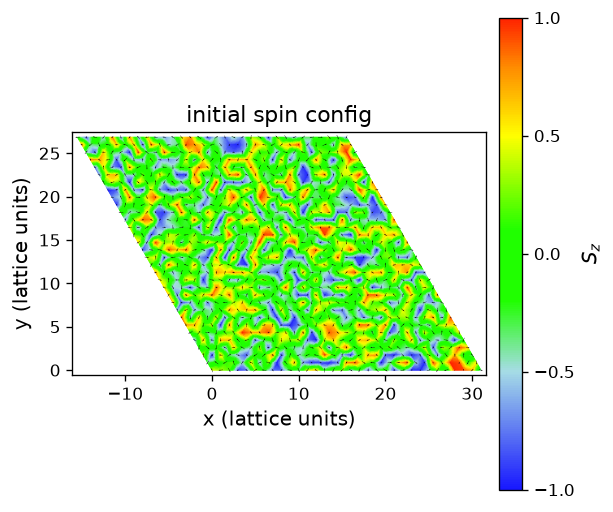

In [12]:
# Current spin configuration: Sz background and in-plane spin arrows.
ax = plot_spin_texture(
    nix2_mc.spin_config, nix2_mc.lat,
    title="initial spin config", figsize=(5, 5),
)
plt.show()

### Step 5 : Prepare for MC Simulation

In [13]:
from nix2_mc_protocols import *

In [14]:
# temperatures
TK_init_list = [70, 50, 19]
TK_final_list = [51, 20, 1]
cooling_method_list = ["linear", "linear", "linear"]
cooling_rate_list = [10, 36, 10]

TK_list = set_temperature_schedule(
    TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list,
)

In [15]:
num_eq_sweeps = 20000
converg_per_every = 10
num_meas_sweeps = 20000
meas_per_every = 5

In [18]:
obs = ["Q", "chi", "P", "M", "E", "Cv"]
measurements = make_measurements(
    nix2_mc,
    observables = obs,
)

In [20]:
mc_parameters={
    # lattice parameters
    "Nx": Na,
    "Ny": Nb,
    "Ns": nix2_model.Ns,
    "geometry": lattice_geometry,
    
    # model parameters
    "model_params": model_params,

    # Monte Carlo parameters
    "seed": mc_seed,
    "num_eq_sweeps": num_eq_sweeps, 
    "converg_per_every": converg_per_every,
    "num_meas_sweeps": num_meas_sweeps, 
    "meas_per_every": meas_per_every,
    "temperatures_info":(TK_init_list, TK_final_list, cooling_method_list, cooling_rate_list),
    "observables": obs,
    "reset_probability": 0.02,
}

current_folder = create_run_folder(root="nix2_simulation_results", parameters=mc_parameters,
                                    prefix="NiX2_topological_charge_")

### Step 6 : start Monte Carlo Simulation

In [21]:
results = run_mc_annealing(
    nix2_mc, TK_list, current_folder,
    num_eq_sweeps=num_eq_sweeps,
    num_meas_sweeps=num_meas_sweeps,
    meas_per_every=meas_per_every,
    converg_per_every=converg_per_every,
    observables=["Q", "E", "P", "M", "chi", "Cv"],
    Nmuc=Nmuc,
)

T = 70.00 K, topological_charge = 0.1075, topological_charge_squared = 36.1705, energy = -9119.860361, electric_polarization = [-2.278267  0.312411 -0.061659], magnetization_norm = 0.022746, magnetization = [-0.000789  0.000644 -0.000811], chi = 0.008615, heat_capacity = 0.954512
T = 67.89 K, topological_charge = 0.00425, topological_charge_squared = 37.39575, energy = -9257.920807, electric_polarization = [ 0.152127 -0.734973 -0.031231], magnetization_norm = 0.023046, magnetization = [-0.000796 -0.000262  0.001169], chi = 0.009258, heat_capacity = 0.855772
T = 65.78 K, topological_charge = -0.14675, topological_charge_squared = 35.41475, energy = -9453.030001, electric_polarization = [ 0.040299  2.558827 -0.145435], magnetization_norm = 0.022073, magnetization = [ 4.976730e-05 -6.973923e-04 -1.053594e-03], chi = 0.00878, heat_capacity = 0.933212
T = 63.67 K, topological_charge = 0.068, topological_charge_squared = 36.4225, energy = -9618.526431, electric_polarization = [0.099752 0.441

### Step 7 : Plotting final spin configuration

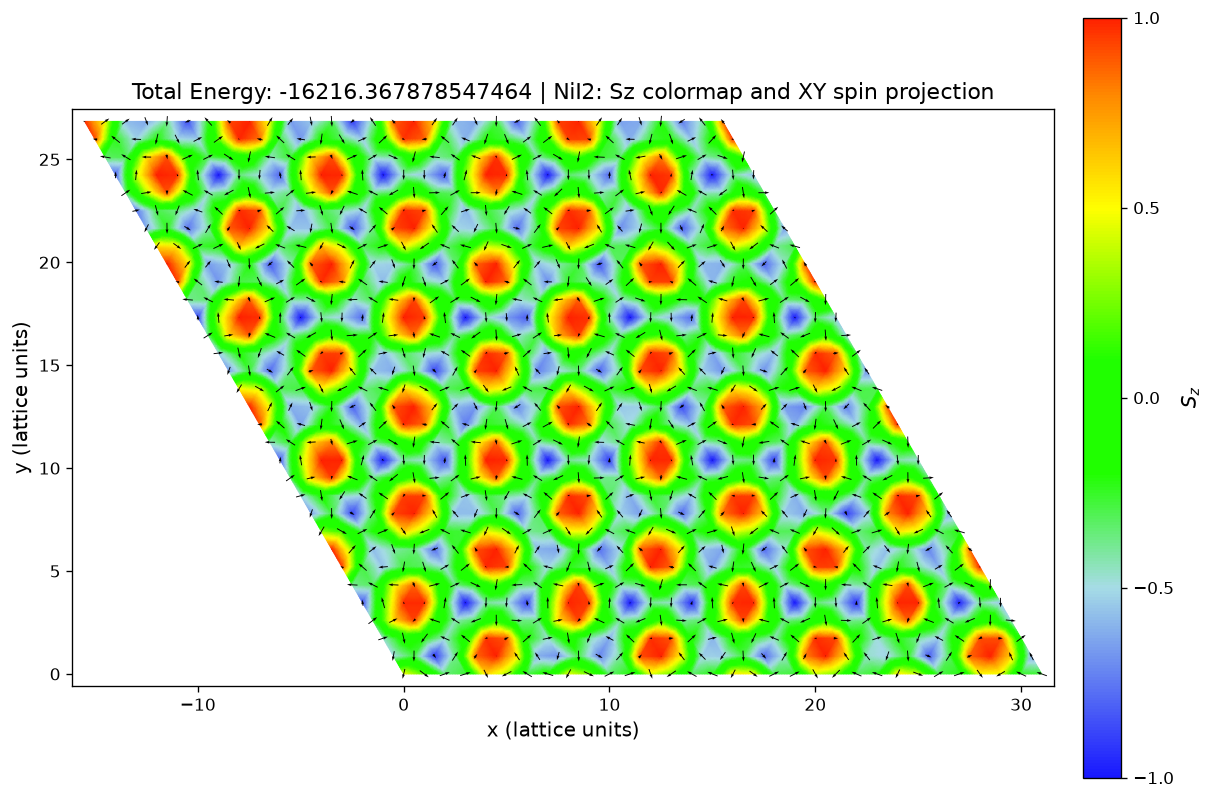

In [22]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=nix2_mc.spin_config,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: Sz colormap and XY spin projection",
    figsize=(10, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
)
plt.show()

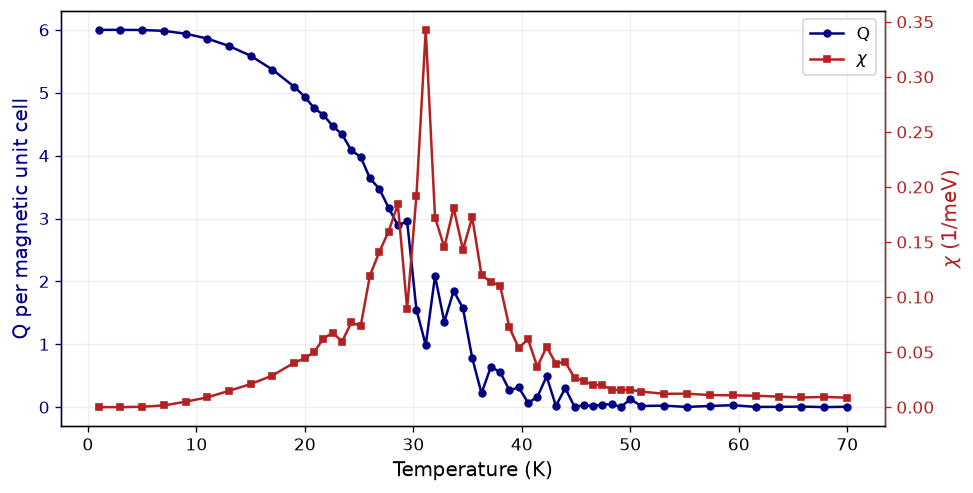

In [24]:
from plotting_3d_spins import plot_curves

fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], abs(results["Q_data"]), results["chi_data"],
    xlabel="Temperature (K)",
    ylabel1="Q per magnetic unit cell", ylabel2=r"$\chi$ (1/meV)",
    label1="Q", label2=r"$\chi$",
    flag_show=True,
)

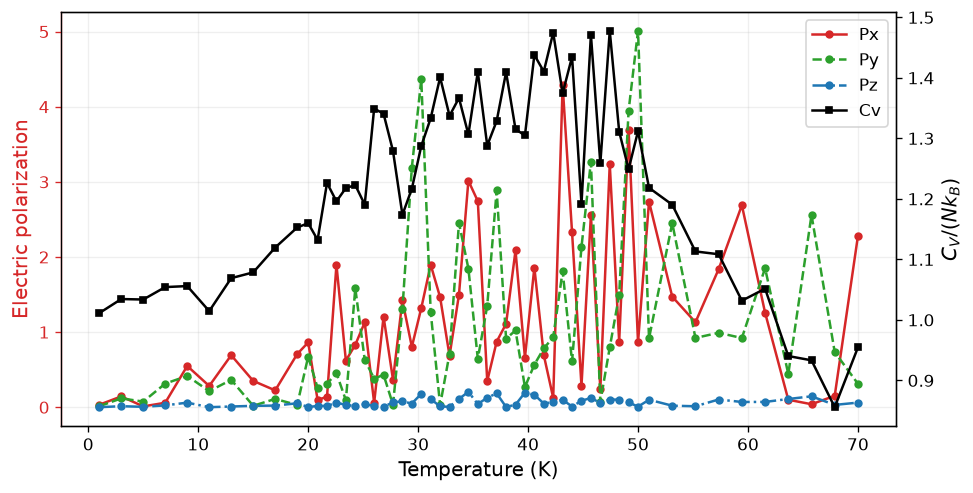

In [25]:
fig, ax1, ax2 = plot_curves(
    results["temperatures_K_list"], np.abs(results["P_data"]).T, results["Cv_data"],
    xlabel="Temperature (K)",
    ylabel1="Electric polarization", ylabel2=r"$C_V/(N k_B)$",
    label1=["Px", "Py", "Pz"], label2="Cv",
    colors=(["tab:red", "tab:green", "tab:blue"], "black"),
    flag_show=True,
)

### Step 8 : LLG relaxation to reach the local minimum

In [26]:
from nix2_llg import get_torques, LLG_relaxation, relax_spins

In [27]:
alpha = 0.5
t_end = 100.0  # ps
energy_before_llg = nix2_mc.total_energy()
# relax spins using LLG
spins_llg = relax_spins(nix2_mc.spin_config, nix2_mc.ham,
                        alpha=alpha, t_end=t_end)

# update the spin configuration
nix2_mc.spin_config = spins_llg.copy()

# compute total energy and maximum torque after relaxation
total_energy = nix2_mc.total_energy()
max_rate = np.max(np.linalg.norm(
    get_torques(alpha, spins_llg, nix2_ham=nix2_mc.ham), axis=-1))
print(f"Energy: {energy_before_llg:.6f} -> {total_energy:.6f} meV")
print(f"Max |dS/dt| = {max_rate:.3e} ps^-1")

Energy: -16216.367879 -> -16307.506885 meV
Max |dS/dt| = 6.797e-06 ps^-1


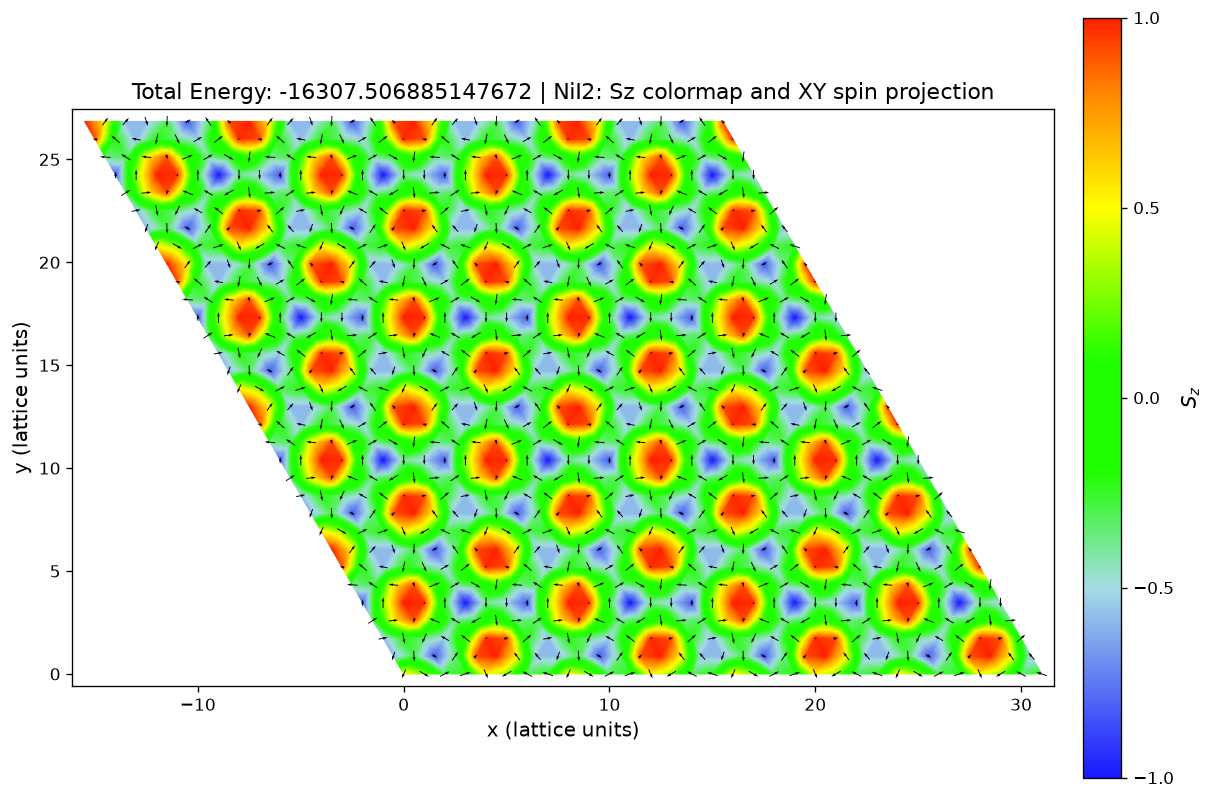

In [28]:
total_energy = nix2_mc.total_energy()

ax = plot_spin_texture(
    spins=spins_llg,
    lattice=nix2_mc.lat,
    title=f"Total Energy: {total_energy} | NiI2: Sz colormap and XY spin projection",
    figsize=(10, 8),
    arrow_scale=1.8,
    arrow_width=0.045,
)
plt.show()

### Old Codes ( ignore )

In [14]:
# S_q_data = []
# Q_data = []
# chi_data = []
# polarization_data = []

# N_total = nix2_mc.lat.N_total

# # set proposal angle for the current temperature

# for temperature_index, temperature_K in enumerate(TK_list):
#     temperature_in_meV = temperature_K * KB_MEV_PER_K
#     nix2_mc.set_proposal_angle(T_in_meV=temperature_in_meV)
    
#     convergence_data = []
#     stat_Q_data = []
#     stat_Q2_data = []
#     stat_P_data = []

#     # ================================
#     # equilibration sweeps
#     # ================================
#     for sweep in range(num_eq_sweeps):
#         nix2_mc.mc_sweep(temperature_in_meV)
#         if sweep % converg_per_every == 0:
#             E_tot = nix2_mc.total_energy()
#             convergence_data.append((E_tot))

#     # ================================
#     # measurement sweeps
#     # ================================
#     for sweep in range(num_meas_sweeps):
#         nix2_mc.mc_sweep(temperature_in_meV)
#         if sweep % meas_per_every == 0:
#             Q, Q2 = nix2_mc.topological_charge()
#             # chi = (Q2 - Q**2) / temperature_in_meV # don't use it, this is exactly 0
#             stat_Q_data.append(Q)
#             stat_Q2_data.append(Q2)
#             P = nix2_mc.electric_polarization()
#             stat_P_data.append(P)

#     # ================================
#     # statistical analysis
#     # ================================
#     # statistical average of Q
#     Q_now = np.mean(stat_Q_data)
#     Q_data.append(Q_now/(Nmuc**2)) # divided by the number of magnetic unit cells

#     absQ_now = np.mean(np.abs(stat_Q_data))
#     chi_now = (np.mean(stat_Q2_data) - absQ_now**2)/(Nmuc**4 * temperature_in_meV)
#     chi_data.append(chi_now)
#     P_now = np.mean(stat_P_data)
#     polarization_data.append(P_now)

#     # spin structure factor
#     # q1, q2, S_q = nix2_mc.spin_structure_factor()
#     # S_q_data.append(S_q)

#     # # print information
#     # print(f"Temperature (K): {temperature_K}, <Q>: {np.mean(stat_Q_data)}, <chi>: {(np.mean(stat_Q2_data) - np.mean(stat_Q_data)**2)}, <P>: {P_now}")
#     print(f"{temperature_index+1}/{len(TK_list)}: T={temperature_K:.3f} K, mean |P|={np.mean(np.abs(stat_P_data)):.4f}")

#     # Save immediately after this temperature finishes.
#     save_temperature_results(
#         current_folder, nix2_mc, temperature_index, temperature_K,
#         observables={
#             # "convergence_energy": convergence_data,
#             "topo_Q": stat_Q_data, 
#             "topo_Q2": stat_Q2_data,
#             "electric_polarization": stat_P_data,
#             # "q1": q1, "q2": q2, "spin_structure_factor": S_q,
#         },
#         parameters=None
#     )

1/70: T=70.000 K, mean |P|=12.2793
2/70: T=69.000 K, mean |P|=11.4147
3/70: T=68.000 K, mean |P|=11.7296
4/70: T=67.000 K, mean |P|=12.9438
5/70: T=66.000 K, mean |P|=12.3054
6/70: T=65.000 K, mean |P|=12.9285
7/70: T=64.000 K, mean |P|=11.6894
8/70: T=63.000 K, mean |P|=11.6837
9/70: T=62.000 K, mean |P|=13.2702
10/70: T=61.000 K, mean |P|=12.3852
11/70: T=60.000 K, mean |P|=12.6394
12/70: T=59.000 K, mean |P|=12.5313
13/70: T=58.000 K, mean |P|=12.4049
14/70: T=57.000 K, mean |P|=11.6662
15/70: T=56.000 K, mean |P|=13.5643
16/70: T=55.000 K, mean |P|=12.6901
17/70: T=54.000 K, mean |P|=12.6831
18/70: T=53.000 K, mean |P|=13.1687
19/70: T=52.000 K, mean |P|=12.9402
20/70: T=51.000 K, mean |P|=13.1592
21/70: T=50.000 K, mean |P|=13.1395
22/70: T=49.000 K, mean |P|=14.8409
23/70: T=48.000 K, mean |P|=13.8023
24/70: T=47.000 K, mean |P|=15.3326
25/70: T=46.000 K, mean |P|=16.0894
26/70: T=45.000 K, mean |P|=13.6016
27/70: T=44.000 K, mean |P|=14.2555
28/70: T=43.000 K, mean |P|=15.2583
2